WARNING    'i' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 4. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    'w' is an internal variable of group 'synapses_3', but also exists in the run namespace with the value 0.0. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Spike counts before plasticity: <spikemonitor_1.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step 0.0 ms
Plasticity step 1000.0 ms
Plasticity step 2000.0 ms
Plasticity step 3000.0 ms
Plasticity step 4000.0 ms
Plasticity step 5000.0 ms
Plasticity step 6000.0 ms
Plasticity step 7000.0 ms
Plasticity step 8000.0 ms
Plasticity step 9000.0 ms
Spike counts after run: <spikemonitor_1.count: array([239, 124, 277, 317, 225,  69, 452,  69,  69, 229,  69, 237,  69,
       173, 166,  69,  69,  69,  69,  69], dtype=int32)>
Number of synapses: 380


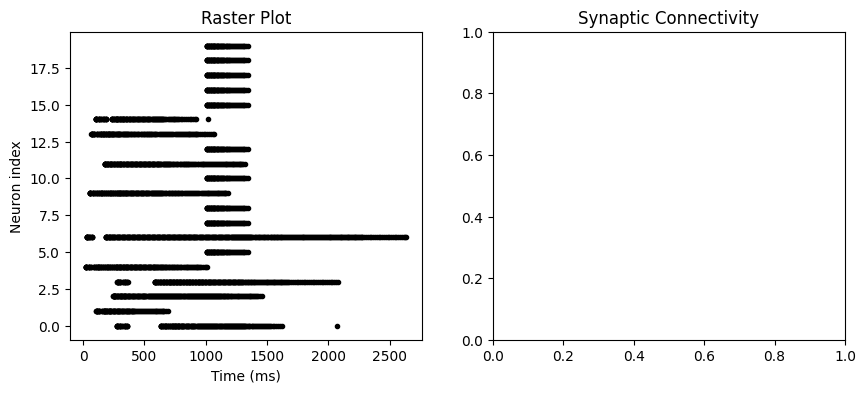

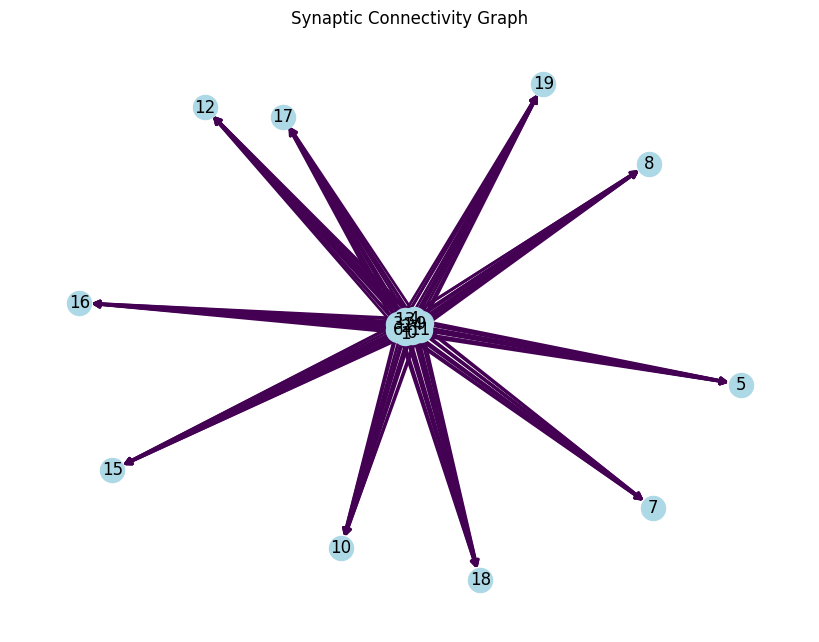

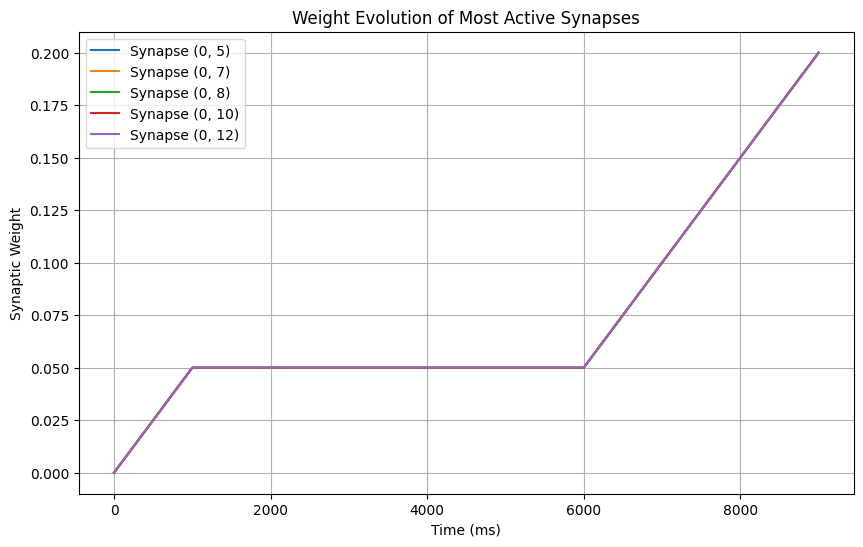

In [2]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
target_rate = 10*Hz
weight_trace = {}
times = []

# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=10, replace=False)
P_input = PoissonGroup(10, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(10), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')

S_rec.connect(condition='i != j')
S_rec.w[:] = 0.0  # initial weights

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 100 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print("Plasticity step", defaultclock.t/ms, "ms")
    for u in underactive:
        for o in overactive:
            if o == u:
                continue  # skip self-connection
            S_rec.w[o, u] = clip(S_rec.w[o, u] + 0.05, 0, 1.0)

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# Network graph
print(f"Number of synapses: {len(S_rec.i[:])}")

plt.subplot(122)
plt.title("Synaptic Connectivity")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.title("Synaptic Connectivity Graph")
    plt.show()

def find_most_active_synapses(weight_trace):
    # Calculate the change in weight for each synapse
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)  # max change
    
    # Sort synapses by the largest change in weight
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    
    # Select top N active synapses to monitor (e.g., top 5)
    top_synapses = [synapse for synapse, _ in most_active[:5]]
    
    return top_synapses

top_synapses = find_most_active_synapses(weight_trace)

# Plot their weight evolution
plt.figure(figsize=(10, 6))

for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')

plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()


In [3]:
stim_indices

array([ 7, 17,  8, 14,  1, 13,  6, 19, 11, 18])

WARNING    'w' is an internal variable of group 'synapses_5', but also exists in the run namespace with the value 0.10000000000000002. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step 0.0 ms
Plasticity step 1000.0 ms
Plasticity step 2000.0 ms
Plasticity step 3000.0 ms
Plasticity step 4000.0 ms
Plasticity step 5000.0 ms
Plasticity step 6000.0 ms
Plasticity step 7000.0 ms
Plasticity step 8000.0 ms
Plasticity step 9000.0 ms
Spike counts after run: <spikemonitor.count: array([ 16, 208,  16, 167, 261,  16, 196, 262, 235, 270,  16, 318, 187,
       227, 273, 262, 268, 271,  16, 230], dtype=int32)>
Number of synapses: 380


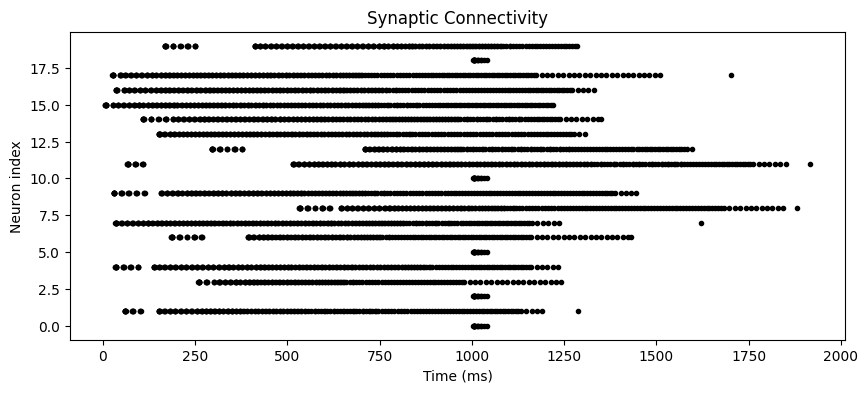

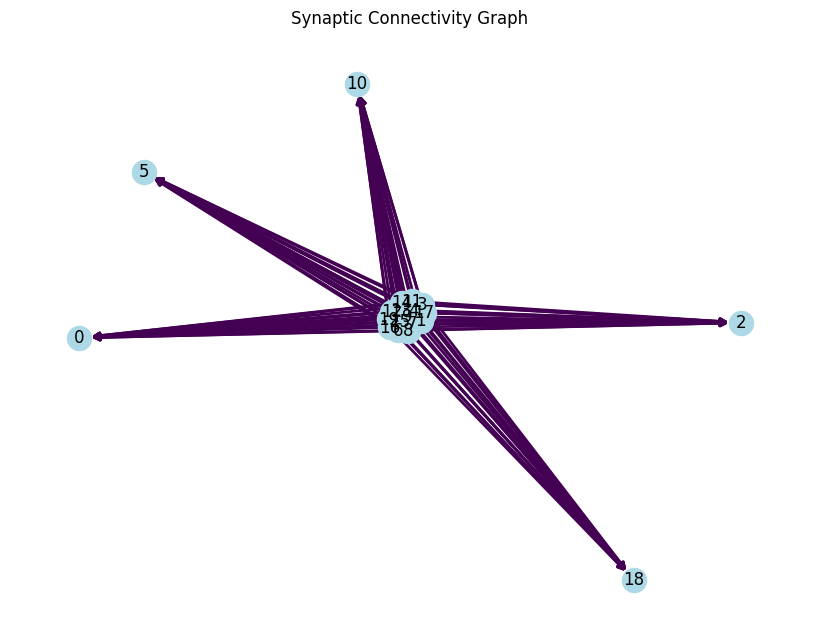

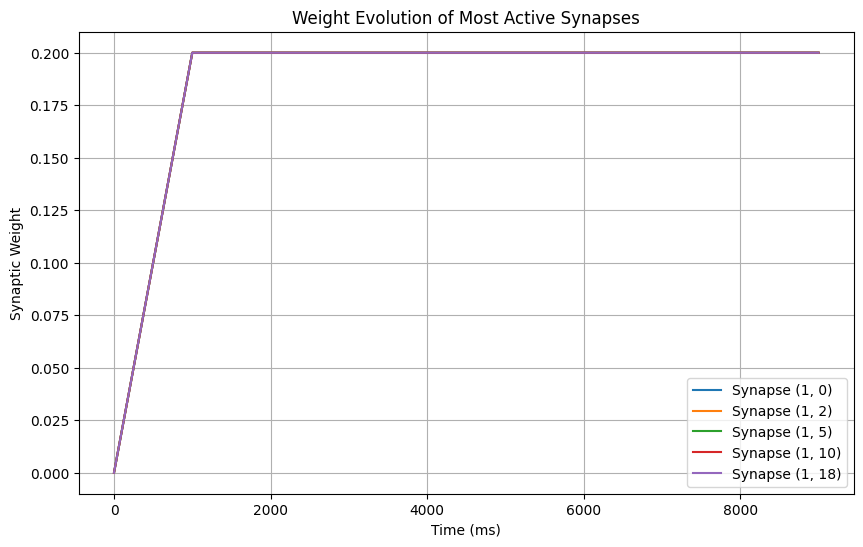

In [6]:
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
target_rate = 10*Hz
weight_trace = {}
times = []

# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=15, replace=False)
P_input = PoissonGroup(15, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(15), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')

S_rec.connect(condition='i != j')
S_rec.w[:] = 0.0  # initial weights

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 100 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print("Plasticity step", defaultclock.t/ms, "ms")

    for u in underactive:
        for o in overactive:
            if o == u:
                continue
            S_rec.w[o, u] = clip(S_rec.w[o, u] + 0.05, 0, 1.0)

    # --- Synaptic normalization (preserve total output per neuron) ---
    for o in range(N):
        outgoing = S_rec.w[o, :]  # outgoing weights from neuron o
        total = sum(outgoing)
        if total > 0:
            S_rec.w[o, :] = outgoing / total  # normalize to total=1.0


@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# Raster plot
plt.figure(figsize=(10, 4))
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# Network graph
print(f"Number of synapses: {len(S_rec.i[:])}")

plt.title("Synaptic Connectivity")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.title("Synaptic Connectivity Graph")
    plt.show()

def find_most_active_synapses(weight_trace):
    # Calculate the change in weight for each synapse
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)  # max change
    
    # Sort synapses by the largest change in weight
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    
    # Select top N active synapses to monitor (e.g., top 5)
    top_synapses = [synapse for synapse, _ in most_active[:5]]
    
    return top_synapses

top_synapses = find_most_active_synapses(weight_trace)

# Plot their weight evolution
plt.figure(figsize=(10, 6))

for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')

plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()


WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.2702821132369177. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]


Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>
Plasticity step 0.0 ms
Plasticity step 1000.0 ms
Plasticity step 2000.0 ms
Plasticity step 3000.0 ms
Plasticity step 4000.0 ms
Plasticity step 5000.0 ms
Plasticity step 6000.0 ms
Plasticity step 7000.0 ms
Plasticity step 8000.0 ms
Plasticity step 9000.0 ms
Spike counts after run: <spikemonitor.count: array([  239, 64982, 64042, 64804,   179, 62688, 64398, 64634, 64518,
       64687, 64451, 65478, 65093, 64481, 62689, 64837, 64627, 64988,
       65213, 65320], dtype=int32)>
Number of synapses: 70


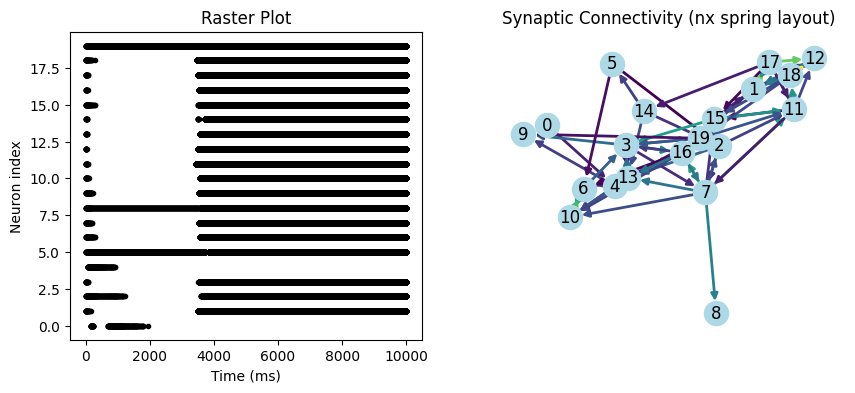

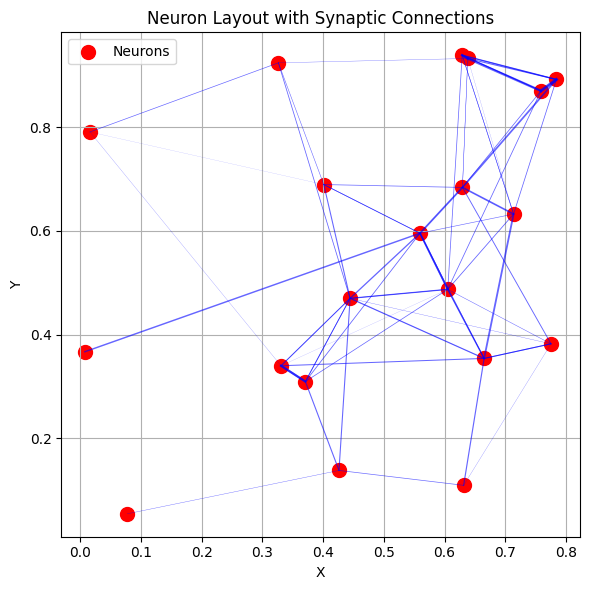

WARNING    /tmp/ipykernel_2303/962454612.py:167: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  weight_changes[(i, j)] = max(weights) - min(weights)
 [py.warnings]
WARNING    /tmp/ipykernel_2303/962454612.py:168: DeprecationWarning: The truth value of an empty array is ambiguous. Returning False, but in future this will result in an error. Use `array.size > 0` to check that an array is not empty.
  most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
 [py.warnings]


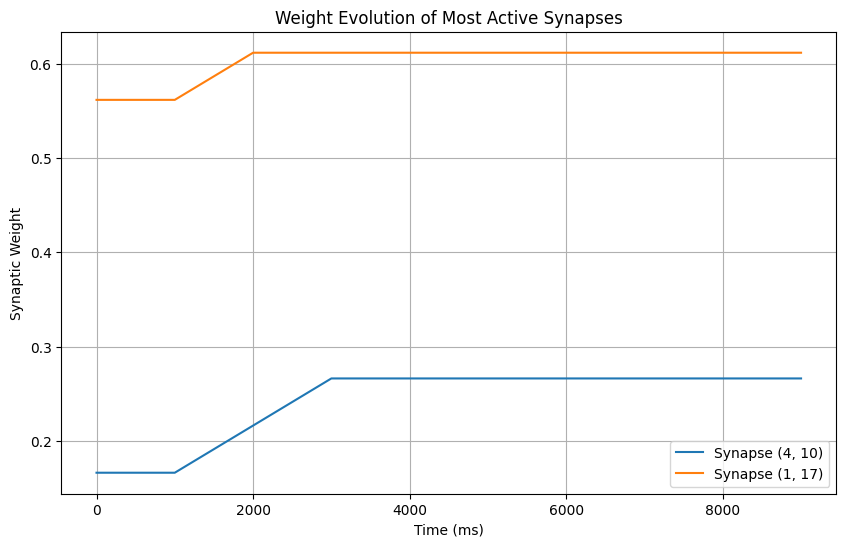

In [5]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
duration = 10*second
target_rate = 10*Hz
weight_trace = {}
times = []

# Spatial layout
neuron_positions = np.random.rand(N, 2)
dist_matrix = cdist(neuron_positions, neuron_positions)

# Probabilistic connection mask
sigma = 0.2
connection_prob = np.exp(-dist_matrix**2 / (2 * sigma**2))
np.fill_diagonal(connection_prob, 0)
connect_mask = np.random.rand(N, N) < connection_prob

# Distance-based initial weights
mean_weight = 0.5 * np.exp(-dist_matrix / sigma)
std_weight = 0.1
weight_matrix = np.random.normal(loc=mean_weight, scale=std_weight)
weight_matrix = np.clip(weight_matrix, 0, 1)
weight_matrix *= connect_mask

# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=10, replace=False)
P_input = PoissonGroup(10, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(10), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')
S_rec.connect(i=np.where(connect_mask)[0], j=np.where(connect_mask)[1])
S_rec.w[:] = weight_matrix[connect_mask]

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 100 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print("Plasticity step", defaultclock.t/ms, "ms")
    for u in underactive:
        for o in overactive:
            if o == u:
                continue  # skip self-connection
            S_rec.w[o, u] = clip(S_rec.w[o, u] + 0.05, 0, 1.0)

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")


# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()



Spike counts before plasticity: <spikemonitor.count: array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
      dtype=int32)>


WARNING    'w' is an internal variable of group 'synapses', but also exists in the run namespace with the value 0.01519818961756973. The internal variable will be used. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    /home/vincent/bmnn/lib/python3.12/site-packages/brian2/units/fundamentalunits.py:1583: RuntimeWarning: invalid value encountered in divide
  rdiv = lambda a, b: operator.truediv(b, a)
 [py.warnings]


Plasticity step at 0.0 ms
Pruned 380 synapses at t=0 ms
Plasticity step at 1000.0 ms
Plasticity step at 2000.0 ms
Pruned 327 synapses at t=2000 ms
Plasticity step at 3000.0 ms
Plasticity step at 4000.0 ms
Pruned 327 synapses at t=4000 ms
Plasticity step at 5000.0 ms
Plasticity step at 6000.0 ms
Pruned 327 synapses at t=6000 ms
Plasticity step at 7000.0 ms
Plasticity step at 8000.0 ms
Pruned 327 synapses at t=8000 ms
Plasticity step at 9000.0 ms
Spike counts after run: <spikemonitor.count: array([ 2775,   210,  2635,   227,  2578,  2949,  2953,   152,   276,
        2808, 15854,  2429, 14390,  2276,  2587,  2622,   208,  2830,
        2928,   246], dtype=int32)>
Number of synapses: 380


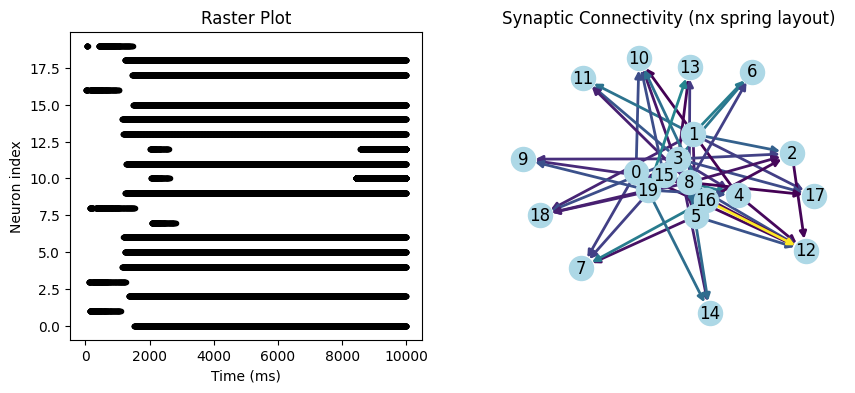

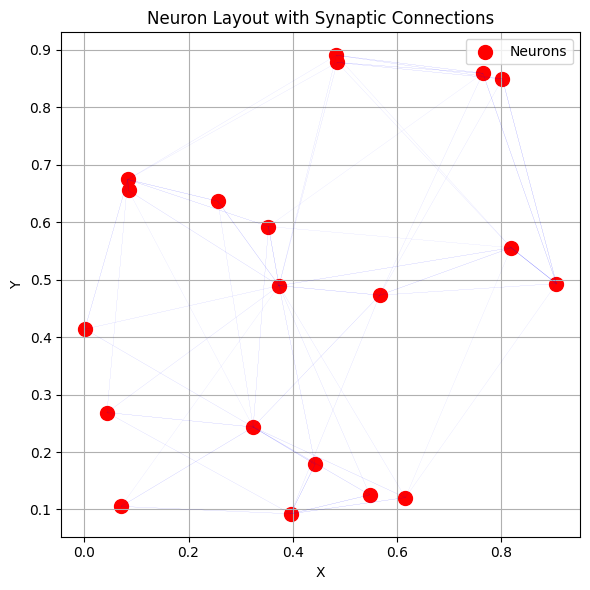

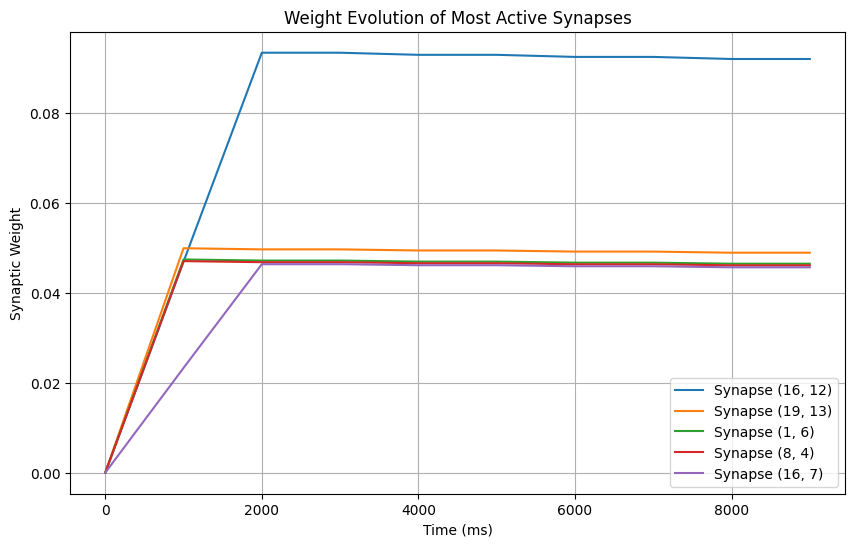

In [ ]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx

start_scope()

# Neuron and simulation parameters
N = 20  # number of excitatory neurons
N_stim = 5
duration = 10*second
target_rate = 10*Hz
weight_trace = {}
times = []

neuron_positions = np.random.rand(N, 2)

def gaussian_weight(distance, sigma=0.3):
    return np.exp(-distance**2 / (2 * sigma**2))


# HH model equations
eqs = '''
dv/dt = (I_inj/area - gNa*m**3*h*(v - ENa) - gK*n**4*(v - EK) - gL*(v - EL)) / Cm : volt
dm/dt = alpham*(1 - m) - betam*m : 1
dn/dt = alphan*(1 - n) - betan*n : 1
dh/dt = alphah*(1 - h) - betah*h : 1
alpham = 0.1*(v/mV + 40)/(1 - exp(-(v/mV + 40)/10))/ms : Hz
betam = 4*exp(-(v/mV + 65)/18)/ms : Hz
alphah = 0.07*exp(-(v/mV + 65)/20)/ms : Hz
betah = 1/(1 + exp(-(v/mV + 35)/10))/ms : Hz
alphan = 0.01*(v/mV + 55)/(1 - exp(-(v/mV + 55)/10))/ms : Hz
betan = 0.125*exp(-(v/mV + 65)/80)/ms : Hz
I_inj : amp
'''

# Constants
Cm = 1*uF/cm**2
gNa = 120*msiemens/cm**2
gK = 36*msiemens/cm**2
gL = 0.3*msiemens/cm**2
ENa = 50*mV
EK = -77*mV
EL = -54.4*mV
area = 20000*umetre**2

# Neuron group
neurons = NeuronGroup(N, eqs, threshold='v > -20*mV', reset='v = -65*mV',
                      method='exponential_euler')
neurons.v = -65*mV
neurons.m = 0.05
neurons.h = 0.6
neurons.n = 0.32
neurons.I_inj = 0*nA

# Poisson input to 15 random neurons
stim_indices = np.random.choice(N, size=N_stim, replace=False)
P_input = PoissonGroup(N_stim, rates=10*Hz)
S_input = Synapses(P_input, neurons, on_pre='I_inj_post += 1.5*nA')
S_input.connect(i=range(N_stim), j=stim_indices)

# Recurrent synapses (initially sparse, plastic)
S_rec = Synapses(neurons, neurons,
                 '''
                 w : 1
                 ''',
                 on_pre='I_inj_post += w*nA')
S_rec.connect(condition='i != j') 
S_rec.w[:] = 0.0

# Spike monitor
spikes = SpikeMonitor(neurons)
rate_monitor = PopulationRateMonitor(neurons)

# Homeostatic plasticity (updates every 1000 ms)
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms")

    for u in underactive:
        for o in overactive:
            if o == u:
                continue
            dist = np.linalg.norm(neuron_positions[o] - neuron_positions[u])

            if dist > 0.5:  # adjust threshold as needed
                continue
            scale = gaussian_weight(dist)
            new_weight = clip(S_rec.w[o, u] + 0.05 * scale, 0, 1.0)
            S_rec.w[o, u] = new_weight
            
@network_operation(dt=2000*ms)
def weight_decay():
    decay_rate = 0.005  # percent decay per second
    S_rec.w[:] *= (1 - decay_rate)
    prune_threshold = 0.001
    S_rec.w[S_rec.w < prune_threshold] = 0
    num_pruned = np.sum(S_rec.w[:] < prune_threshold)
    print(f"Pruned {num_pruned} synapses at t={defaultclock.t/ms:.0f} ms")

@network_operation(dt=1000*ms)
def record_weights():
    times.append(defaultclock.t/ms)
    
    # Record the weight of each synapse
    for i in range(N):
        for j in range(N):
            if i != j:
                weight = S_rec.w[i, j]
                if (i, j) not in weight_trace:
                    weight_trace[(i, j)] = []
                weight_trace[(i, j)].append(weight)

print(f"Spike counts before plasticity: {spikes.count}")
run(duration)
print(f"Spike counts after run: {spikes.count}")

# 1. Raster plot
plt.figure(figsize=(10, 4))
plt.subplot(121)
plt.title("Raster Plot")
plt.plot(spikes.t/ms, spikes.i, '.k')
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')

# 2. Synaptic connectivity graph
print(f"Number of synapses: {len(S_rec.i[:])}")
plt.subplot(122)
plt.title("Synaptic Connectivity (nx spring layout)")
G = nx.DiGraph()
G.add_nodes_from(range(N))
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        G.add_edge(int(src), int(tgt), weight=w)
if G.number_of_edges() == 0:
    print("Warning: Graph has no edges.")
else:
    pos = nx.spring_layout(G)
    weights = [G[u][v]['weight'] for u, v in G.edges()]
    nx.draw(G, pos, with_labels=True, node_color='lightblue',
            edge_color=weights, edge_cmap=plt.cm.viridis,
            width=2, arrowsize=10)
    plt.show()

# 3. Neuron layout with connection lines based on weights
plt.figure(figsize=(6, 6))
plt.title("Neuron Layout with Synaptic Connections")
for src, tgt in zip(S_rec.i[:], S_rec.j[:]):
    pos_src = neuron_positions[src]
    pos_tgt = neuron_positions[tgt]
    w = float(S_rec.w[src, tgt][0])
    if w > 0:
        plt.plot([pos_src[0], pos_tgt[0]], [pos_src[1], pos_tgt[1]],
                 alpha=0.6, linewidth=w*3, color='blue')
plt.scatter(neuron_positions[:, 0], neuron_positions[:, 1], c='red', s=100, label='Neurons')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# 4. Weight evolution of most active synapses
def find_most_active_synapses(weight_trace):
    weight_changes = {}
    for (i, j), weights in weight_trace.items():
        weight_changes[(i, j)] = max(weights) - min(weights)
    most_active = sorted(weight_changes.items(), key=lambda item: item[1], reverse=True)
    return [synapse for synapse, _ in most_active[:5]]

top_synapses = find_most_active_synapses(weight_trace)

plt.figure(figsize=(10, 6))
for synapse in top_synapses:
    synaptic_weight = weight_trace[synapse]
    plt.plot(times, synaptic_weight, label=f'Synapse ({synapse[0]}, {synapse[1]})')
plt.xlabel('Time (ms)')
plt.ylabel('Synaptic Weight')
plt.title('Weight Evolution of Most Active Synapses')
plt.legend()
plt.grid(True)
plt.show()



WARNING    /tmp/ipykernel_2303/3696886108.py:82: RuntimeWarning: invalid value encountered in divide
  rates = spikes.count[:N_e] / defaultclock.t
 [py.warnings]


Plasticity step at 0.0 ms
Plasticity step at 1000.0 ms
Plasticity step at 2000.0 ms
Plasticity step at 3000.0 ms
Plasticity step at 4000.0 ms
Plasticity step at 5000.0 ms
Plasticity step at 6000.0 ms
Plasticity step at 7000.0 ms
Plasticity step at 8000.0 ms
Plasticity step at 9000.0 ms


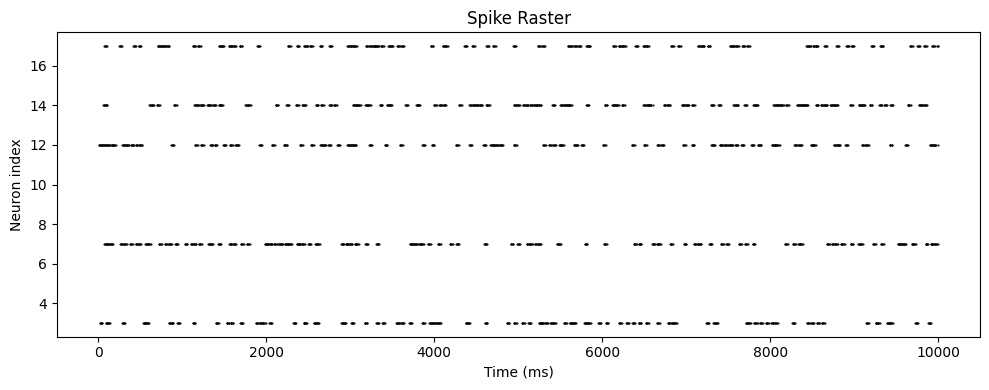

In [ ]:
from scipy.spatial.distance import cdist
from brian2 import *
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
start_scope()

# Simulation parameters
N_e = 20
N_i = 5
N = N_e + N_i
simulation_time = 10*second

# Neuron model parameters
E_l = -60*mV
E_e = 0*mV
E_i = -80*mV
V_th = -50*mV
V_r = E_l
g_l = 9.99*nS
C_m = 198*pF
tau_e = 5*ms
tau_i = 10*ms
tau_r = 5*ms
tau_inj = 10*ms


# Synaptic parameters
initial_weight = 0*nS
w_i = 1.0*nS

# Target firing rate
target_rate = 5*Hz

# Distance-based Gaussian weight scaling
def gaussian_weight(dist, sigma=0.2):
    return np.exp(-dist**2 / (2*sigma**2))

# Neuron positions in 2D space
neuron_positions = np.random.rand(N, 2)

# Neuron model
eqs = '''
dv/dt = (g_l*(E_l - v) + g_e*(E_e - v) + g_i*(E_i - v)+ I_inj) / C_m : volt (unless refractory)
dg_e/dt = -g_e / tau_e : siemens
dg_i/dt = -g_i / tau_i : siemens
dI_inj/dt = -I_inj / tau_inj : amp
'''

neurons = NeuronGroup(N, model=eqs, threshold='v > V_th', reset='v = V_r',
                      refractory=tau_r, method='euler')
neurons.v = 'E_l + rand() * (V_th - E_l)'
neurons.I_inj = 0*nA

exc_neurons = neurons[:N_e]
inh_neurons = neurons[N_e:]

# Poisson stimulation for a few excitatory neurons
n_stim = 10
stim_indices = np.random.choice(N_e, size=N_stim, replace=False)
P_input = PoissonGroup(N_stim, rates=10*Hz)
S_input = Synapses(P_input, exc_neurons, on_pre='I_inj_post += 10.5*nA')
S_input.connect(i=range(N_stim), j=stim_indices)

# Recurrent excitatory synapses with plasticity
S_rec = Synapses(exc_neurons, exc_neurons, 'w : siemens',
                 on_pre='g_e_post += w')
S_rec.connect(condition='i != j')
S_rec.w = initial_weight

# Inhibitory feedback
S_inh = Synapses(inh_neurons, neurons, on_pre='g_i_post += w_i')
S_inh.connect(p=0.2)

# # Monitors
# spikes = SpikeMonitor(neurons)
# state_mon = StateMonitor(neurons, 'v', record=S_input[0])
exc_mon = SpikeMonitor(exc_neurons)
inh_mon = SpikeMonitor(inh_neurons)


state_mon = StateMonitor(exc_neurons, ['v', 'g_e', 'g_i'])

synapse_mon = StateMonitor(exc_syn, ['u_S', 'x_S'],
                           record=exc_syn, when='after_synapses')


# Homeostatic plasticity rule
@network_operation(dt=1000*ms)
def homeostatic_plasticity():
    rates = spikes.count[:N_e] / defaultclock.t
    underactive = np.where(rates < target_rate)[0]
    overactive = np.where(rates >= target_rate)[0]
    print(f"Plasticity step at {defaultclock.t/ms:.1f} ms")

    for u in underactive:
        for o in overactive:
            if o == u:
                continue
            dist = np.linalg.norm(neuron_positions[o] - neuron_positions[u])
            if dist > 0.5:
                continue
            scale = gaussian_weight(dist)
            new_weight = clip(S_rec.w[o, u] + 0.05*nS * scale, 0*nS, 1.0*nS)
            S_rec.w[o, u] = new_weight

# Run simulation
run(simulation_time)

# # Plot spike raster
# plt.figure(figsize=(10, 4))
# plt.plot(spikes.t/ms, spikes.i, '.k', markersize=1)
# plt.xlabel('Time (ms)')
# plt.ylabel('Neuron index')
# plt.title('Spike Raster')
# plt.tight_layout()
# plt.show()

In [ ]:
plt.style.use('figures.mplstyle')

### Spiking activity (w/ rate)
fig1, ax = plt.subplots(nrows=2, ncols=1, sharex=False,
                        gridspec_kw={'height_ratios': [3, 1],
                                     'left': 0.18, 'bottom': 0.18, 'top': 0.95,
                                     'hspace': 0.1},
                        figsize=(3.07, 3.07))
ax[0].plot(exc_mon.t[exc_mon.i <= N_e//4]/ms,
           exc_mon.i[exc_mon.i <= N_e//4], '|', color='C0')
ax[0].plot(inh_mon.t[inh_mon.i <= N_i//4]/ms,
           inh_mon.i[inh_mon.i <= N_i//4]+N_e//4, '|', color='C1')
pu.adjust_spines(ax[0], ['left'])
ax[0].set(xlim=(0., duration/ms), ylim=(0, (N_e+N_i)//4), ylabel='neuron index')

# Generate frequencies
bin_size = 1*ms
spk_count, bin_edges = np.histogram(np.r_[exc_mon.t/ms, inh_mon.t/ms],
                                    int(duration/ms))
rate = double(spk_count)/(N_e + N_i)/bin_size/Hz
ax[1].plot(bin_edges[:-1], rate, '-', color='k')
pu.adjust_spines(ax[1], ['left', 'bottom'])
ax[1].set(xlim=(0., duration/ms), ylim=(0, 10.),
          xlabel='time (ms)', ylabel='rate (Hz)')
pu.adjust_ylabels(ax, x_offset=-0.18)

### Dynamics of a single neuron
fig2, ax = plt.subplots(4, sharex=False,
                       gridspec_kw={'left': 0.27, 'bottom': 0.18, 'top': 0.95,
                                    'hspace': 0.2},
                       figsize=(3.07, 3.07))
### Postsynaptic conductances
ax[0].plot(state_mon.t/ms, state_mon.g_e[0]/nS, color='C0')
ax[0].plot(state_mon.t/ms, -state_mon.g_i[0]/nS, color='C1')
ax[0].plot([state_mon.t[0]/ms, state_mon.t[-1]/ms], [0, 0], color='grey',
           linestyle=':')
# Adjust axis
pu.adjust_spines(ax[0], ['left'])
ax[0].set(xlim=(0., duration/ms), ylim=(-5.0, 0.25),
          ylabel=f"postsyn.\nconduct.\n(${sympy.latex(nS)}$)")

### Membrane potential
ax[1].axhline(V_th/mV, color='C2', linestyle=':')  # Threshold
# Artificially insert spikes
ax[1].plot(state_mon.t/ms, state_mon.v[0]/mV, color='black')
ax[1].vlines(exc_mon.t[exc_mon.i == ni]/ms, V_th/mV, 0, color='black')
pu.adjust_spines(ax[1], ['left'])
ax[1].set(xlim=(0., duration/ms), ylim=(-1+V_r/mV, 0.),
          ylabel=f"membrane\npotential\n(${sympy.latex(mV)}$)")

### Synaptic variables
# Retrieves indexes of spikes in the synaptic monitor using the fact that we
# are sampling spikes and synaptic variables by the same dt
spk_index = np.in1d(synapse_mon.t, exc_mon.t[exc_mon.i == ni])
ax[2].plot(synapse_mon.t[spk_index]/ms, synapse_mon.x_S[0][spk_index], '.',
           ms=4, color='C3')
ax[2].plot(synapse_mon.t[spk_index]/ms, synapse_mon.u_S[0][spk_index], '.',
           ms=4, color='C4')
# Super-impose reconstructed solutions
time = synapse_mon.t  # time vector
tspk = Quantity(synapse_mon.t, copy=True)  # Spike times
for ts in exc_mon.t[exc_mon.i == ni]:
    tspk[time >= ts] = ts
ax[2].plot(synapse_mon.t/ms, 1 + (synapse_mon.x_S[0]-1)*exp(-(time-tspk)*Omega_d),
           '-', color='C3')
ax[2].plot(synapse_mon.t/ms, synapse_mon.u_S[0]*exp(-(time-tspk)*Omega_f),
           '-', color='C4')
# Adjust axis
pu.adjust_spines(ax[2], ['left'])
ax[2].set(xlim=(0., duration/ms), ylim=(-0.05, 1.05),
          ylabel='synaptic\nvariables\n$u_S,\,x_S$')

nspikes = np.sum(spk_index)
x_S_spike = synapse_mon.x_S[0][spk_index]
u_S_spike = synapse_mon.u_S[0][spk_index]
ax[3].vlines(synapse_mon.t[spk_index]/ms, np.zeros(nspikes),
             x_S_spike*u_S_spike/(1-u_S_spike))
pu.adjust_spines(ax[3], ['left', 'bottom'])
ax[3].set(xlim=(0., duration/ms), ylim=(-0.01, 0.62),
          yticks=np.arange(0, 0.62, 0.2), xlabel='time (ms)', ylabel='$r_S$')

pu.adjust_ylabels(ax, x_offset=-0.20)


plt.show()